# Computational Lab 4 — From Brownian motion to Maxwell–Boltzmann and Drude transport

Overdamped Brownian motion has no explicit velocity, so it cannot by itself
produce a velocity distribution or electrical drift. The missing bridge is the
**underdamped Langevin equation**. This lab uses it to recover three limits of
one model:

1. Maxwell–Boltzmann equilibrium in velocity space;
2. ballistic-to-Brownian motion in position space; and
3. Drude drift and conductivity in an electric field.

We use representative nondegenerate semiconductor parameters. The model is
classical; the final section explains why a degenerate metal requires the
Drude–Sommerfeld correction.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "lecture-notes" / "main.tex").exists()
)
OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})

## 1. The common microscopic model

For one Cartesian component,

\[
    dX=V\,dt,
    \qquad
    dV=-\frac{V}{\tau}\,dt+\frac{qE}{m^*}\,dt
       +\sqrt{\frac{2k_BT}{m^*\tau}}\,dW.
\]

The relaxation time $\tau$ describes momentum loss in collisions. The random
force restores thermal fluctuations. Their linked strengths constitute the
fluctuation–dissipation relation.

For constant $E$, velocity is an Ornstein–Uhlenbeck process. Over one time
step its exact update is

\[
 V_{r+1}=v_d+a(V_r-v_d)
       +v_{\rm th}\sqrt{1-a^2}\,\xi_r,
\]

where $a=e^{-\Delta t/\tau}$, $v_{\rm th}=\sqrt{k_BT/m^*}$,
$v_d=qE\tau/m^*$, and $\xi_r\sim\mathcal N(0,1)$. We use a trapezoidal position
update; the small step makes its position-integration error negligible.

In [2]:
# Physical parameters in SI units.
boltzmann = 1.380_649e-23          # J/K
elementary_charge = 1.602_176_634e-19  # C
electron_mass = 9.109_383_7139e-31     # kg
temperature = 300.0               # K
effective_mass = 0.26 * electron_mass
relaxation_time = 0.20e-12        # s
carrier_density = 1.0e21          # m^-3
charge = -elementary_charge

thermal_velocity = np.sqrt(boltzmann * temperature / effective_mass)
diffusivity_theory = boltzmann * temperature * relaxation_time / effective_mass
mobility_theory = elementary_charge * relaxation_time / effective_mass
conductivity_theory = carrier_density * elementary_charge**2 * relaxation_time / effective_mass

print(f"one-component thermal speed = {thermal_velocity:.3e} m/s")
print(f"Einstein diffusivity        = {diffusivity_theory:.3e} m^2/s")
print(f"positive mobility           = {mobility_theory:.3e} m^2/(V s)")
print(f"Drude conductivity          = {conductivity_theory:.3e} S/m")

one-component thermal speed = 1.322e+05 m/s
Einstein diffusivity        = 3.498e-03 m^2/s
positive mobility           = 1.353e-01 m^2/(V s)
Drude conductivity          = 2.168e+01 S/m


## 2. Zero-field equilibrium: Maxwell–Boltzmann velocities

At $E=0$, the stationary velocity density in three dimensions is

\[
 f(\mathbf v)=
 \left(\frac{m^*}{2\pi k_BT}\right)^{3/2}
 \exp\!\left(-\frac{m^*|\mathbf v|^2}{2k_BT}\right).
\]

Each component is Gaussian with variance $k_BT/m^*$. Consequently,
$\tfrac12m^*\langle|\mathbf v|^2\rangle=\tfrac32k_BT$. We initialize at this
equilibrium and verify that Langevin dynamics preserves it.

In [3]:
rng = np.random.default_rng(62714)
particle_count = 40_000
steps_per_relaxation_time = 50
time_step = relaxation_time / steps_per_relaxation_time
final_time = 10.0 * relaxation_time
step_count = round(final_time / time_step)
time = time_step * np.arange(step_count + 1)
decay_factor = np.exp(-time_step / relaxation_time)
velocity_noise = thermal_velocity * np.sqrt(1.0 - decay_factor**2)
shown_particle_count = 10

velocity = thermal_velocity * rng.standard_normal((particle_count, 3))
position_x = np.zeros(particle_count)
shown_paths = np.zeros((step_count + 1, shown_particle_count))
mean_square_displacement = np.zeros(step_count + 1)
velocity_correlation = np.zeros(step_count + 1)
initial_velocity_x = velocity[:, 0].copy()
velocity_correlation[0] = np.mean(initial_velocity_x**2)

for step in range(1, step_count + 1):
    old_velocity_x = velocity[:, 0].copy()
    velocity = (
        decay_factor * velocity
        + velocity_noise * rng.standard_normal((particle_count, 3))
    )
    position_x += 0.5 * (old_velocity_x + velocity[:, 0]) * time_step
    shown_paths[step] = position_x[:shown_particle_count]
    mean_square_displacement[step] = np.mean(position_x**2)
    velocity_correlation[step] = np.mean(velocity[:, 0] * initial_velocity_x)

speed = np.linalg.norm(velocity, axis=1)
kinetic_energy_mean = 0.5 * effective_mass * np.mean(speed**2)
expected_kinetic_energy = 1.5 * boltzmann * temperature

assert np.isclose(np.mean(velocity[:, 0]), 0.0, atol=0.02 * thermal_velocity)
assert np.isclose(np.var(velocity[:, 0]), thermal_velocity**2, rtol=0.02)
assert np.isclose(kinetic_energy_mean, expected_kinetic_energy, rtol=0.02)

print(f"simulated <K> / (3 kT/2) = {kinetic_energy_mean / expected_kinetic_energy:.5f}")
print(f"simulated var(Vx)/(kT/m*) = {np.var(velocity[:, 0]) / thermal_velocity**2:.5f}")

simulated <K> / (3 kT/2) = 1.00215
simulated var(Vx)/(kT/m*) = 1.00768


## 3. Ballistic motion becomes Brownian diffusion

For an equilibrium Langevin particle,

\[
 \langle V(t)V(0)\rangle=\frac{k_BT}{m^*}e^{-t/\tau},
\]

and

\[
 \langle\Delta X^2(t)\rangle=
 2D\left[t-\tau\left(1-e^{-t/\tau}\right)\right],
 \qquad D=\frac{k_BT\tau}{m^*}.
\]

At $t\ll\tau$ the MSD is ballistic, $(k_BT/m^*)t^2$. At $t\gg\tau$ it
approaches the Brownian law $2Dt$. Thus ordinary Brownian motion is the
long-time, velocity-relaxed limit of the thermal gas.

In [4]:
msd_theory = 2.0 * diffusivity_theory * (
    time - relaxation_time * (1.0 - np.exp(-time / relaxation_time))
)
correlation_theory = thermal_velocity**2 * np.exp(-time / relaxation_time)
long_time = time >= 5.0 * relaxation_time
msd_slope, _ = np.polyfit(time[long_time], mean_square_displacement[long_time], 1)
diffusivity_measured = msd_slope / 2.0

assert np.isclose(diffusivity_measured, diffusivity_theory, rtol=0.04)
print(f"D from long-time MSD = {diffusivity_measured:.4e} m^2/s")
print(f"D from kT tau / m*   = {diffusivity_theory:.4e} m^2/s")
print(f"relative difference  = {diffusivity_measured / diffusivity_theory - 1:+.2%}")

D from long-time MSD = 3.5226e-03 m^2/s
D from kT tau / m*   = 3.4976e-03 m^2/s
relative difference  = +0.71%


## 4. Apply a field: the Drude gas

Averaging the Langevin equation removes the zero-mean noise:

\[
 m^*\frac{d\langle V\rangle}{dt}
 =qE-\frac{m^*}{\tau}\langle V\rangle.
\]

After switching on a constant field,

\[
 \langle V(t)\rangle=v_d(1-e^{-t/\tau}),
 \qquad v_d=\frac{q\tau}{m^*}E.
\]

The particle flux is $\Gamma=n\langle V\rangle$, while the conventional charge
current is $j=q\Gamma$. Electron drift is opposite $E$, but multiplying by the
negative electron charge makes conventional current parallel to $E$.

In [5]:
electric_field = 2.0e5             # V/m
drift_velocity_theory = charge * electric_field * relaxation_time / effective_mass
field_velocity = thermal_velocity * rng.standard_normal(particle_count)
mean_drift_velocity = np.zeros(step_count + 1)

for step in range(1, step_count + 1):
    field_velocity = (
        drift_velocity_theory
        + decay_factor * (field_velocity - drift_velocity_theory)
        + velocity_noise * rng.standard_normal(particle_count)
    )
    mean_drift_velocity[step] = np.mean(field_velocity)

mean_drift_theory = drift_velocity_theory * (
    1.0 - np.exp(-time / relaxation_time)
)
measured_drift_velocity = np.mean(mean_drift_velocity[-100:])
measured_mobility = abs(measured_drift_velocity) / electric_field
measured_current_density = carrier_density * charge * measured_drift_velocity
measured_conductivity = measured_current_density / electric_field

assert np.isclose(measured_drift_velocity, drift_velocity_theory, rtol=0.04)
assert np.isclose(measured_conductivity, conductivity_theory, rtol=0.04)
assert np.isclose(
    diffusivity_theory,
    mobility_theory * boltzmann * temperature / elementary_charge,
)

print(f"theoretical electron drift = {drift_velocity_theory:.4e} m/s")
print(f"measured electron drift    = {measured_drift_velocity:.4e} m/s")
print(f"measured current density   = {measured_current_density:.4e} A/m^2")
print(f"measured conductivity      = {measured_conductivity:.4e} S/m")
print(f"measured mobility          = {measured_mobility:.4e} m^2/(V s)")

theoretical electron drift = -2.7059e+04 m/s
measured electron drift    = -2.6464e+04 m/s
measured current density   = 4.2400e+06 A/m^2
measured conductivity      = 2.1200e+01 S/m
measured mobility          = 1.3232e-01 m^2/(V s)


## 5. Einstein and Drude relations

The long-time diffusion result and steady drift result share the same
relaxation time:

\[
 D=\frac{k_BT\tau}{m^*},\qquad
 \mu=\frac{|q|\tau}{m^*},\qquad
 \boxed{D=\frac{\mu k_BT}{|q|}}.
\]

For a spatially varying density, drift and diffusion combine as

\[
 \Gamma=-D\nabla n+\frac{q\tau}{m^*}n\mathbf E,
 \qquad \mathbf j=q\Gamma.
\]

The DC Drude conductivity is

\[
 \boxed{\sigma_0=\frac{nq^2\tau}{m^*}}.
\]

For a harmonic field with convention $e^{-i\omega t}$,
$\sigma(\omega)=\sigma_0/(1-i\omega\tau)$.

In [6]:
normalized_frequency = np.logspace(-2, 2, 300)  # omega tau
normalized_ac_conductivity = 1.0 / (1.0 - 1j * normalized_frequency)

# Dimensionless distributions used for plotting.
normalized_velocity_grid = np.linspace(-4.5, 4.5, 400)
gaussian_component = np.exp(-0.5 * normalized_velocity_grid**2) / np.sqrt(2.0 * np.pi)
normalized_speed_grid = np.linspace(0.0, 5.0, 400)
maxwell_speed = np.sqrt(2.0 / np.pi) * normalized_speed_grid**2 * np.exp(
    -0.5 * normalized_speed_grid**2
)

## 6. Results

The panels follow the conceptual chain: inertial trajectories, velocity
thermalization, ballistic-to-diffusive position statistics, Maxwell speed
equilibrium, field-induced Drude drift, and frequency-dependent conductivity.

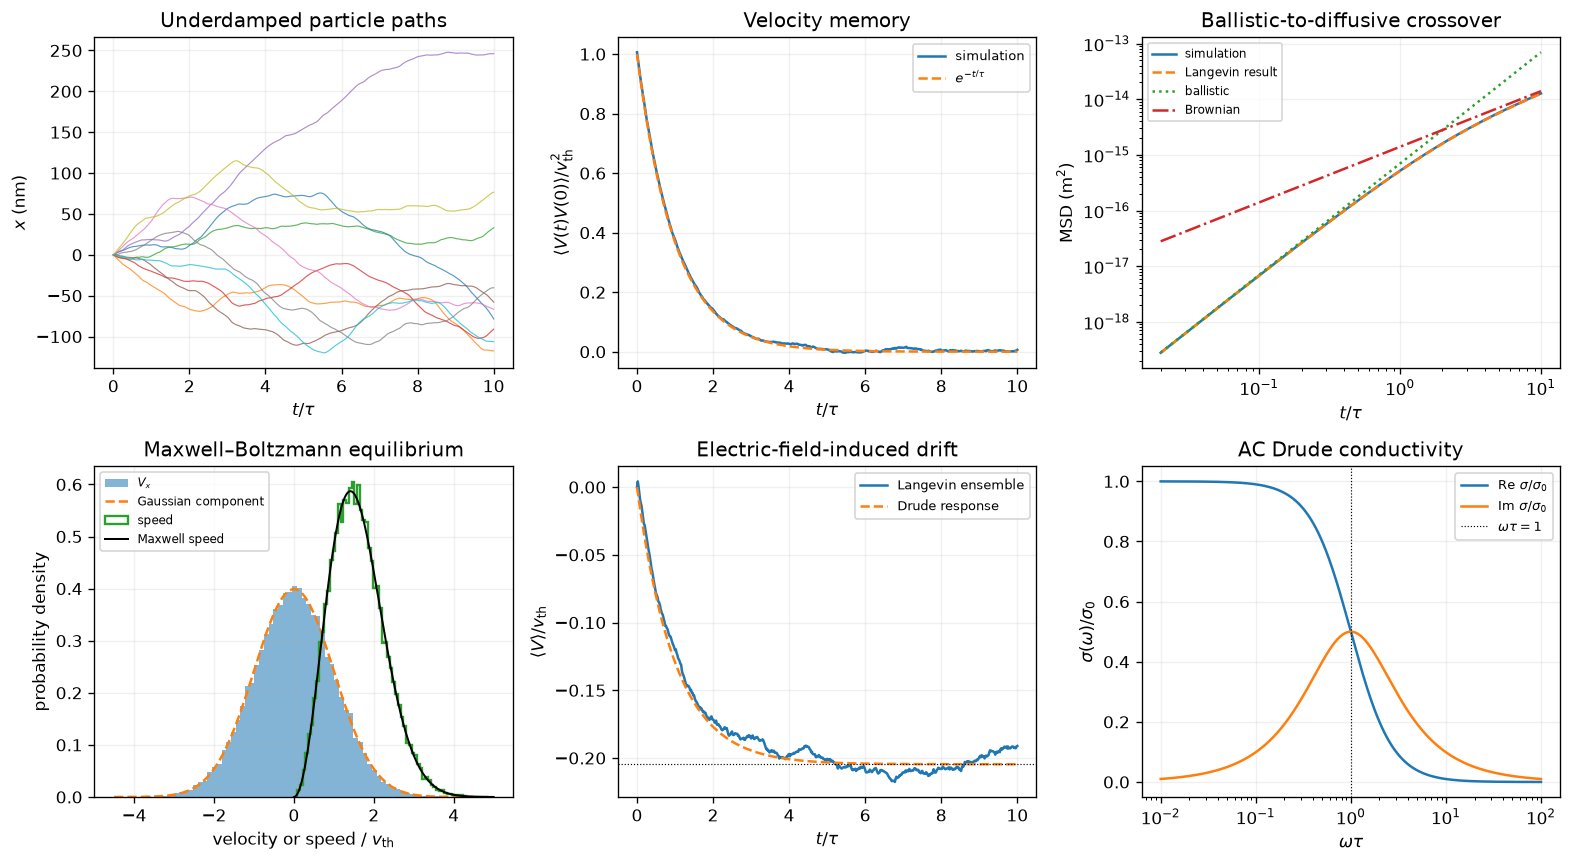

wrote lecture-notes/figures/08_brownian-motion-diffusion/lab-04-langevin-maxwell-boltzmann-drude.pdf


In [7]:
figure, axes = plt.subplots(2, 3, figsize=(13.2, 7.3))
normalized_time = time / relaxation_time

axes[0, 0].plot(normalized_time, 1e9 * shown_paths, linewidth=0.7, alpha=0.75)
axes[0, 0].set(title="Underdamped particle paths", xlabel=r"$t/\tau$", ylabel="$x$ (nm)")

axes[0, 1].plot(normalized_time, velocity_correlation / thermal_velocity**2, label="simulation")
axes[0, 1].plot(normalized_time, correlation_theory / thermal_velocity**2, "--", label=r"$e^{-t/\tau}$")
axes[0, 1].set(title="Velocity memory", xlabel=r"$t/\tau$", ylabel=r"$\langle V(t)V(0)\rangle/v_{\rm th}^2$")
axes[0, 1].legend(fontsize=8)

axes[0, 2].loglog(normalized_time[1:], mean_square_displacement[1:], label="simulation")
axes[0, 2].loglog(normalized_time[1:], msd_theory[1:], "--", label="Langevin result")
axes[0, 2].loglog(normalized_time[1:], thermal_velocity**2 * time[1:]**2, ":", label="ballistic")
axes[0, 2].loglog(normalized_time[1:], 2.0 * diffusivity_theory * time[1:], "-.", label="Brownian")
axes[0, 2].set(title="Ballistic-to-diffusive crossover", xlabel=r"$t/\tau$", ylabel=r"MSD (m$^2$)")
axes[0, 2].legend(fontsize=7)

axes[1, 0].hist(velocity[:, 0] / thermal_velocity, bins=70, density=True, alpha=0.55, label=r"$V_x$")
axes[1, 0].plot(normalized_velocity_grid, gaussian_component, "--", label="Gaussian component")
axes[1, 0].hist(speed / thermal_velocity, bins=70, density=True, histtype="step", linewidth=1.4, label="speed")
axes[1, 0].plot(normalized_speed_grid, maxwell_speed, color="black", linewidth=1.2, label="Maxwell speed")
axes[1, 0].set(title="Maxwell–Boltzmann equilibrium", xlabel=r"velocity or speed / $v_{\rm th}$", ylabel="probability density")
axes[1, 0].legend(fontsize=7)

axes[1, 1].plot(normalized_time, mean_drift_velocity / thermal_velocity, label="Langevin ensemble")
axes[1, 1].plot(normalized_time, mean_drift_theory / thermal_velocity, "--", label="Drude response")
axes[1, 1].axhline(drift_velocity_theory / thermal_velocity, color="black", linewidth=0.7, linestyle=":")
axes[1, 1].set(title="Electric-field-induced drift", xlabel=r"$t/\tau$", ylabel=r"$\langle V\rangle/v_{\rm th}$")
axes[1, 1].legend(fontsize=8)

axes[1, 2].semilogx(normalized_frequency, normalized_ac_conductivity.real, label=r"Re $\sigma/\sigma_0$")
axes[1, 2].semilogx(normalized_frequency, normalized_ac_conductivity.imag, label=r"Im $\sigma/\sigma_0$")
axes[1, 2].axvline(1.0, color="black", linewidth=0.7, linestyle=":", label=r"$\omega\tau=1$")
axes[1, 2].set(title="AC Drude conductivity", xlabel=r"$\omega\tau$", ylabel=r"$\sigma(\omega)/\sigma_0$")
axes[1, 2].legend(fontsize=8)

for axis in axes.flat:
    axis.grid(alpha=0.18)
figure.tight_layout()
output_path = OUTPUT / "lab-04-langevin-maxwell-boltzmann-drude.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": "DLSU SEMPHY01", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")

## 7. Scope and extensions

The classical progression is now explicit:

\[
\text{underdamped Langevin}
\longrightarrow
\begin{cases}
\text{Maxwell--Boltzmann velocities},\\
\text{Brownian diffusion at }t\gg\tau,
\end{cases}
\longrightarrow
\text{Drude drift when }E\neq0.
\]

Suggested investigations:

1. Change `temperature` and verify $v_{\rm th}\propto\sqrt{T}$ and $D\propto T$
   when $\tau$ is held fixed.
2. Change `relaxation_time`. Confirm that velocity memory, diffusivity,
   mobility, and conductivity change consistently.
3. Decrease the field and particle count. Why does extracting a small drift
   from a broad thermal distribution become statistically difficult?
4. Replace the constant field by a sinusoid and measure amplitude and phase.
   Compare with $\sigma(\omega)$.
5. **Model limitation:** electrons in an ordinary metal are generally
   degenerate and follow Fermi–Dirac rather than Maxwell–Boltzmann statistics.
   Drude–Sommerfeld retains relaxation-time transport but uses the Fermi sea;
   mainly states near the Fermi surface respond. The classical notebook is
   most directly applicable to a nondegenerate semiconductor or dilute gas.